# Single-Region Comprehensive Validation Pipeline
This notebook executes an end-to-end evaluation for a single calorimeter kinematic region ($E_T \times \eta$):
1. **Split Manifest & Class Balance**: Analyzes signal (photons) vs background (jets) counts in the holdout test partition.
2. **Feature Distributions & Derived Variables**: Computes and visualizes raw features and calculated shower shapes (including $E_{\text{ratio}}$) with class separations.
3. **Training & Metric Curves**: Aggregates fold repeats and renders training loss, SP index, and ROC curves.
4. **Efficiency Validation**: Evaluates detection efficiency and false-alarm response against baseline thresholds.
5. **Quadrant Analysis (Model vs Cut)**: Benchmarks the best model against Athena fast photon linear cuts.
6. **Feature Distributions with Model Selections**: Overlays accepted events (black dots) on signal/background feature histograms for both the ML model and linear cuts.
7. **Model vs Model Comparison**: Executes holdout quadrant comparison against a secondary model configuration.



In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Resolve repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
import mplhep as mh

mh.style.use("ATLAS")

from src.Parser.NeuralRingerTrainerConfiguration import NeuralRingerTrainerConfiguration
from src.core.Trainers.NeuralRingerTrainer import NeuralRingerTrainer
from src.core.Datasets.SplitManifest import SplitManifest
from src.core.Validation.ResultAggregator import ResultAggregator
from src.core.Validation.HoldoutEvaluator import HoldoutEvaluator, HoldoutEvaluationResult
from src.core.Validation.EfficiencyPlotter import EfficiencyPlotter
from src.core.Validation.QuadrantAnalyzer import QuadrantAnalyzer, StrategyMetrics
from src.core.Plotting.FeatureDistributionPlotter import FeatureDistributionPlotter
from scipy import stats
from src.core.Plotting.QuadrantPlotter import QuadrantPlotter
from src.core.Plotting.PlotManager import PlotManager
from src.utils import (
    get_et_eta,
    save_table,
    extract_feature_values,
    compute_ks_test_with_uncertainty,
    compute_wasserstein_with_uncertainty,
    compute_kl_divergence_with_uncertainty,
    compute_js_divergence_with_uncertainty,
)
from src.core.Validation.DistributionComparator import DistributionComparator

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


Project root: /eos/home-i04/p/pmourafr/egamma_master
PyTorch version: 2.10.0, CUDA available: True


### Centralized Configuration Constants
All parameters, paths, and region selections are defined below:



In [2]:
# --- Target Kinematic Region ---
TARGET_ET: int = 1
TARGET_ETA: int = 1
REGION_KEY: str = f"et_{TARGET_ET}_eta_{TARGET_ETA}"

# --- Validation & Operating Point Constants ---
TARGET_PD: float = 0.9424
EFFICIENCIES_CSV: Path | None = None
THRESHOLD_MODE: str = "calibrated"  # 'calibrated' for target PD cut, 'default' for 0.5 threshold
WORKING_POINT: str = "loose"        # Athena fast photon cut: 'loose', 'medium', 'tight'
PLOT_FORMAT: str = "png"            # 'png' or 'pdf'
LOG_Y_SECTION_6: bool = False  # Enable logarithmic Y-axis scale for Section 6 feature plots

# --- Model 1 (Primary Model) Paths ---
CONFIG_PATH_1: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml"
RESULTS_PATH_1: Path = PROJECT_ROOT / "results/config_nameModelV9_HighBatch_100Rings_id20261029001623"
MODEL_1_ALIAS: str = "Model V9 (100 Rings)"

# --- Model 2 (Secondary Comparison Model) ---
ENABLE_MODEL2_COMPARISON: bool = True
CONFIG_PATH_2: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_50Rings.yaml"
RESULTS_PATH_2: Path = PROJECT_ROOT / "results/config_nameModelV9_HighBatch_50Rings_id20261029022525"
MODEL_2_ALIAS: str = "Model V9 (50 Rings)"

ATHENA_ALIAS: str = f"Athena {WORKING_POINT.capitalize()} Cut"

# --- Common Data & Output Directories ---
DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = RESULTS_PATH_1.parent / "split_manifest.json"
OUTPUT_DIR: Path = PROJECT_ROOT / "notebooks" / f"SingleRegionValidation_{RESULTS_PATH_1.name}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRUE_DATA_PLOTS_DIR: Path = PROJECT_ROOT / "notebooks/TrueDataPlots"
TRUE_DATA_PLOTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR: Path = OUTPUT_DIR / "Tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
TRUE_DATA_TABLES_DIR: Path = TRUE_DATA_PLOTS_DIR / "Tables"
TRUE_DATA_TABLES_DIR.mkdir(parents=True, exist_ok=True)

# --- Features to Inspect & Histogram (including derived Eratio) ---
FEATURES_TO_PLOT: list[str] = [
    "trig_L2_calo_et",
    "trig_L2_calo_eta",
    "trig_L2_calo_phi",
    "trig_L2_calo_e237",
    "trig_L2_calo_e277",
    "trig_L2_calo_fracs1",
    "trig_L2_calo_weta2",
    "trig_L2_calo_ehad1",
    "trig_L2_calo_emaxs1",
    "trig_L2_calo_e2tsts1",
    "trig_L2_calo_wstot",
    "Eratio",
]

print(f"Target Region:        {REGION_KEY} (ET={TARGET_ET}, ETA={TARGET_ETA})")
print(f"Primary Config:       {CONFIG_PATH_1}")
print(f"Primary Results:      {RESULTS_PATH_1}")
print(f"Output Directory:     {OUTPUT_DIR}")
print(f"True Data Plots:      {TRUE_DATA_PLOTS_DIR}")
print(f"Tables Directory:     {TABLES_DIR}")
print(f"True Data Tables:     {TRUE_DATA_TABLES_DIR}")
print(f"Target Efficiency:    {TARGET_PD * 100:.2f}%")
print(f"Athena Working Point: {WORKING_POINT.capitalize()}")
print(f"Features configured:  {len(FEATURES_TO_PLOT)} variables")
print(f"Section 6 Log Y Scale:  {LOG_Y_SECTION_6}")
print(f"Model 1 Alias:        {MODEL_1_ALIAS}")
print(f"Model 2 Alias:        {MODEL_2_ALIAS}")
print(f"Athena Alias:         {ATHENA_ALIAS}")


Target Region:        et_1_eta_1 (ET=1, ETA=1)
Primary Config:       /eos/home-i04/p/pmourafr/egamma_master/config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml
Primary Results:      /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV9_HighBatch_100Rings_id20261029001623
Output Directory:     /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261029001623
True Data Plots:      /eos/home-i04/p/pmourafr/egamma_master/notebooks/TrueDataPlots
Tables Directory:     /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261029001623/Tables
True Data Tables:     /eos/home-i04/p/pmourafr/egamma_master/notebooks/TrueDataPlots/Tables
Target Efficiency:    94.24%
Athena Working Point: Loose
Features configured:  12 variables
Section 6 Log Y Scale:  False
Model 1 Alias:        Model V9 (100 Rings)
Model 2 Alias:        Model V9 (50 Rings)
Athena Alias:         Athen

### 1. Data Loading & Test Set Class Distribution Analysis
Loads dataset samples for the configured region, retrieves the deterministic test partition from [`SplitManifest`](file:///home/pmourafr/egamma_master/src/core/Datasets/SplitManifest.py), and computes class counts:



Loaded dataset file: /eos/home-i04/p/pmourafr/egamma_master/data/consolidated/consolidated.et1.eta1.npz
Total events in region: 143,780


,Partition,Signal (Photons),Background (Jets),Total Events,Signal Fraction,Background Fraction
0,Holdout Test Set,3994,10384,14378,27.78%,72.22%
1,Train / Val Set,35938,93464,129402,27.77%,72.23%
2,Full Region Data,39932,103848,143780,27.77%,72.23%


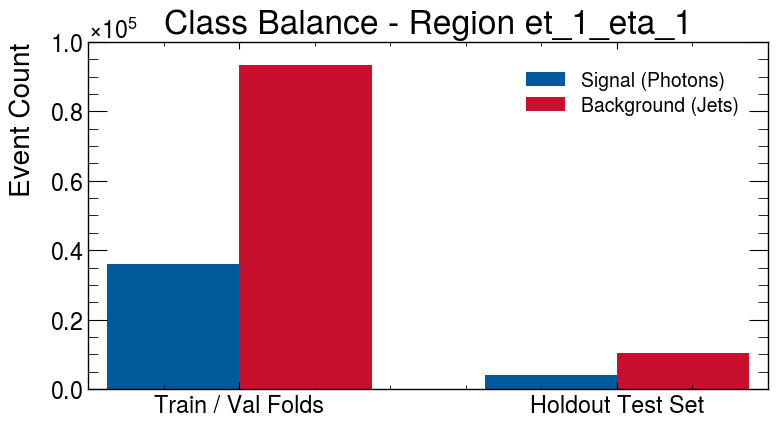

In [3]:
with open(CONFIG_PATH_1, "r") as f:
    config_dict_1 = yaml.safe_load(f)

if DATA_PATH.exists():
    config_dict_1["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)

config_1 = NeuralRingerTrainerConfiguration.model_validate(config_dict_1)
trainer_1 = NeuralRingerTrainer(config_1)
full_dataset = trainer_1.full_dataset

# Locate dataset index matching TARGET_ET and TARGET_ETA
region_file_idx = None
for idx, path_str in enumerate(full_dataset.file_paths):
    iet, ieta = get_et_eta(path_str)
    if iet == TARGET_ET and ieta == TARGET_ETA:
        region_file_idx = idx
        break

if region_file_idx is None:
    raise FileNotFoundError(f"No dataset file matching et={TARGET_ET}, eta={TARGET_ETA} in {DATA_PATH}")

raw_features, raw_labels, region_file_path = full_dataset[region_file_idx]
print(f"Loaded dataset file: {region_file_path}")
print(f"Total events in region: {len(raw_labels):,}")

# Load test split indices from manifest
manifest = SplitManifest(str(MANIFEST_PATH))
if not manifest.exists():
    raise FileNotFoundError(f"Manifest not found at {MANIFEST_PATH}")

manifest.load()
test_indices, train_folds = manifest.get_region_splits(REGION_KEY)
test_indices = np.array(test_indices, dtype=int)

all_indices = np.arange(len(raw_labels))
train_val_mask = ~np.isin(all_indices, test_indices)
test_mask = np.isin(all_indices, test_indices)

test_features = raw_features[test_indices]
test_labels = raw_labels[test_indices]
train_val_labels = raw_labels[train_val_mask]

# Compute class counts
test_sig = int(np.sum(test_labels == 1))
test_bg = int(np.sum(test_labels == 0))
total_test = len(test_labels)

train_sig = int(np.sum(train_val_labels == 1))
train_bg = int(np.sum(train_val_labels == 0))
total_train = len(train_val_labels)

summary_df = pd.DataFrame([
    {
        "Partition": "Holdout Test Set",
        "Signal (Photons)": test_sig,
        "Background (Jets)": test_bg,
        "Total Events": total_test,
        "Signal Fraction": f"{test_sig / total_test:.2%}",
        "Background Fraction": f"{test_bg / total_test:.2%}",
    },
    {
        "Partition": "Train / Val Set",
        "Signal (Photons)": train_sig,
        "Background (Jets)": train_bg,
        "Total Events": total_train,
        "Signal Fraction": f"{train_sig / total_train:.2%}",
        "Background Fraction": f"{train_bg / total_train:.2%}",
    },
    {
        "Partition": "Full Region Data",
        "Signal (Photons)": test_sig + train_sig,
        "Background (Jets)": test_bg + train_bg,
        "Total Events": total_test + total_train,
        "Signal Fraction": f"{(test_sig + train_sig) / (total_test + total_train):.2%}",
        "Background Fraction": f"{(test_bg + train_bg) / (total_test + total_train):.2%}",
    }
])

display(summary_df)
save_table(summary_df, TRUE_DATA_TABLES_DIR, REGION_KEY, "class_distribution_summary")

# Plot class breakdown bar chart
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, [train_sig, test_sig], width, label="Signal (Photons)", color="#005A9C")
ax.bar(x + width/2, [train_bg, test_bg], width, label="Background (Jets)", color="#C8102E")
ax.set_xticks(x)
ax.set_xticklabels(["Train / Val Folds", "Holdout Test Set"])
ax.set_ylabel("Event Count")
ax.set_title(f"Class Balance - Region {REGION_KEY}")
ax.legend()
plt.tight_layout()
plt.show()


### 2. Feature Extraction & Distributions by Class Label
Defines the feature extractor (supporting raw columns and calculated variables like $E_{\text{ratio}} = (E_{\text{max1}} - E_{\text{max2}}) / (E_{\text{max1}} + E_{\text{max2}})$) and plots signal vs background histograms:



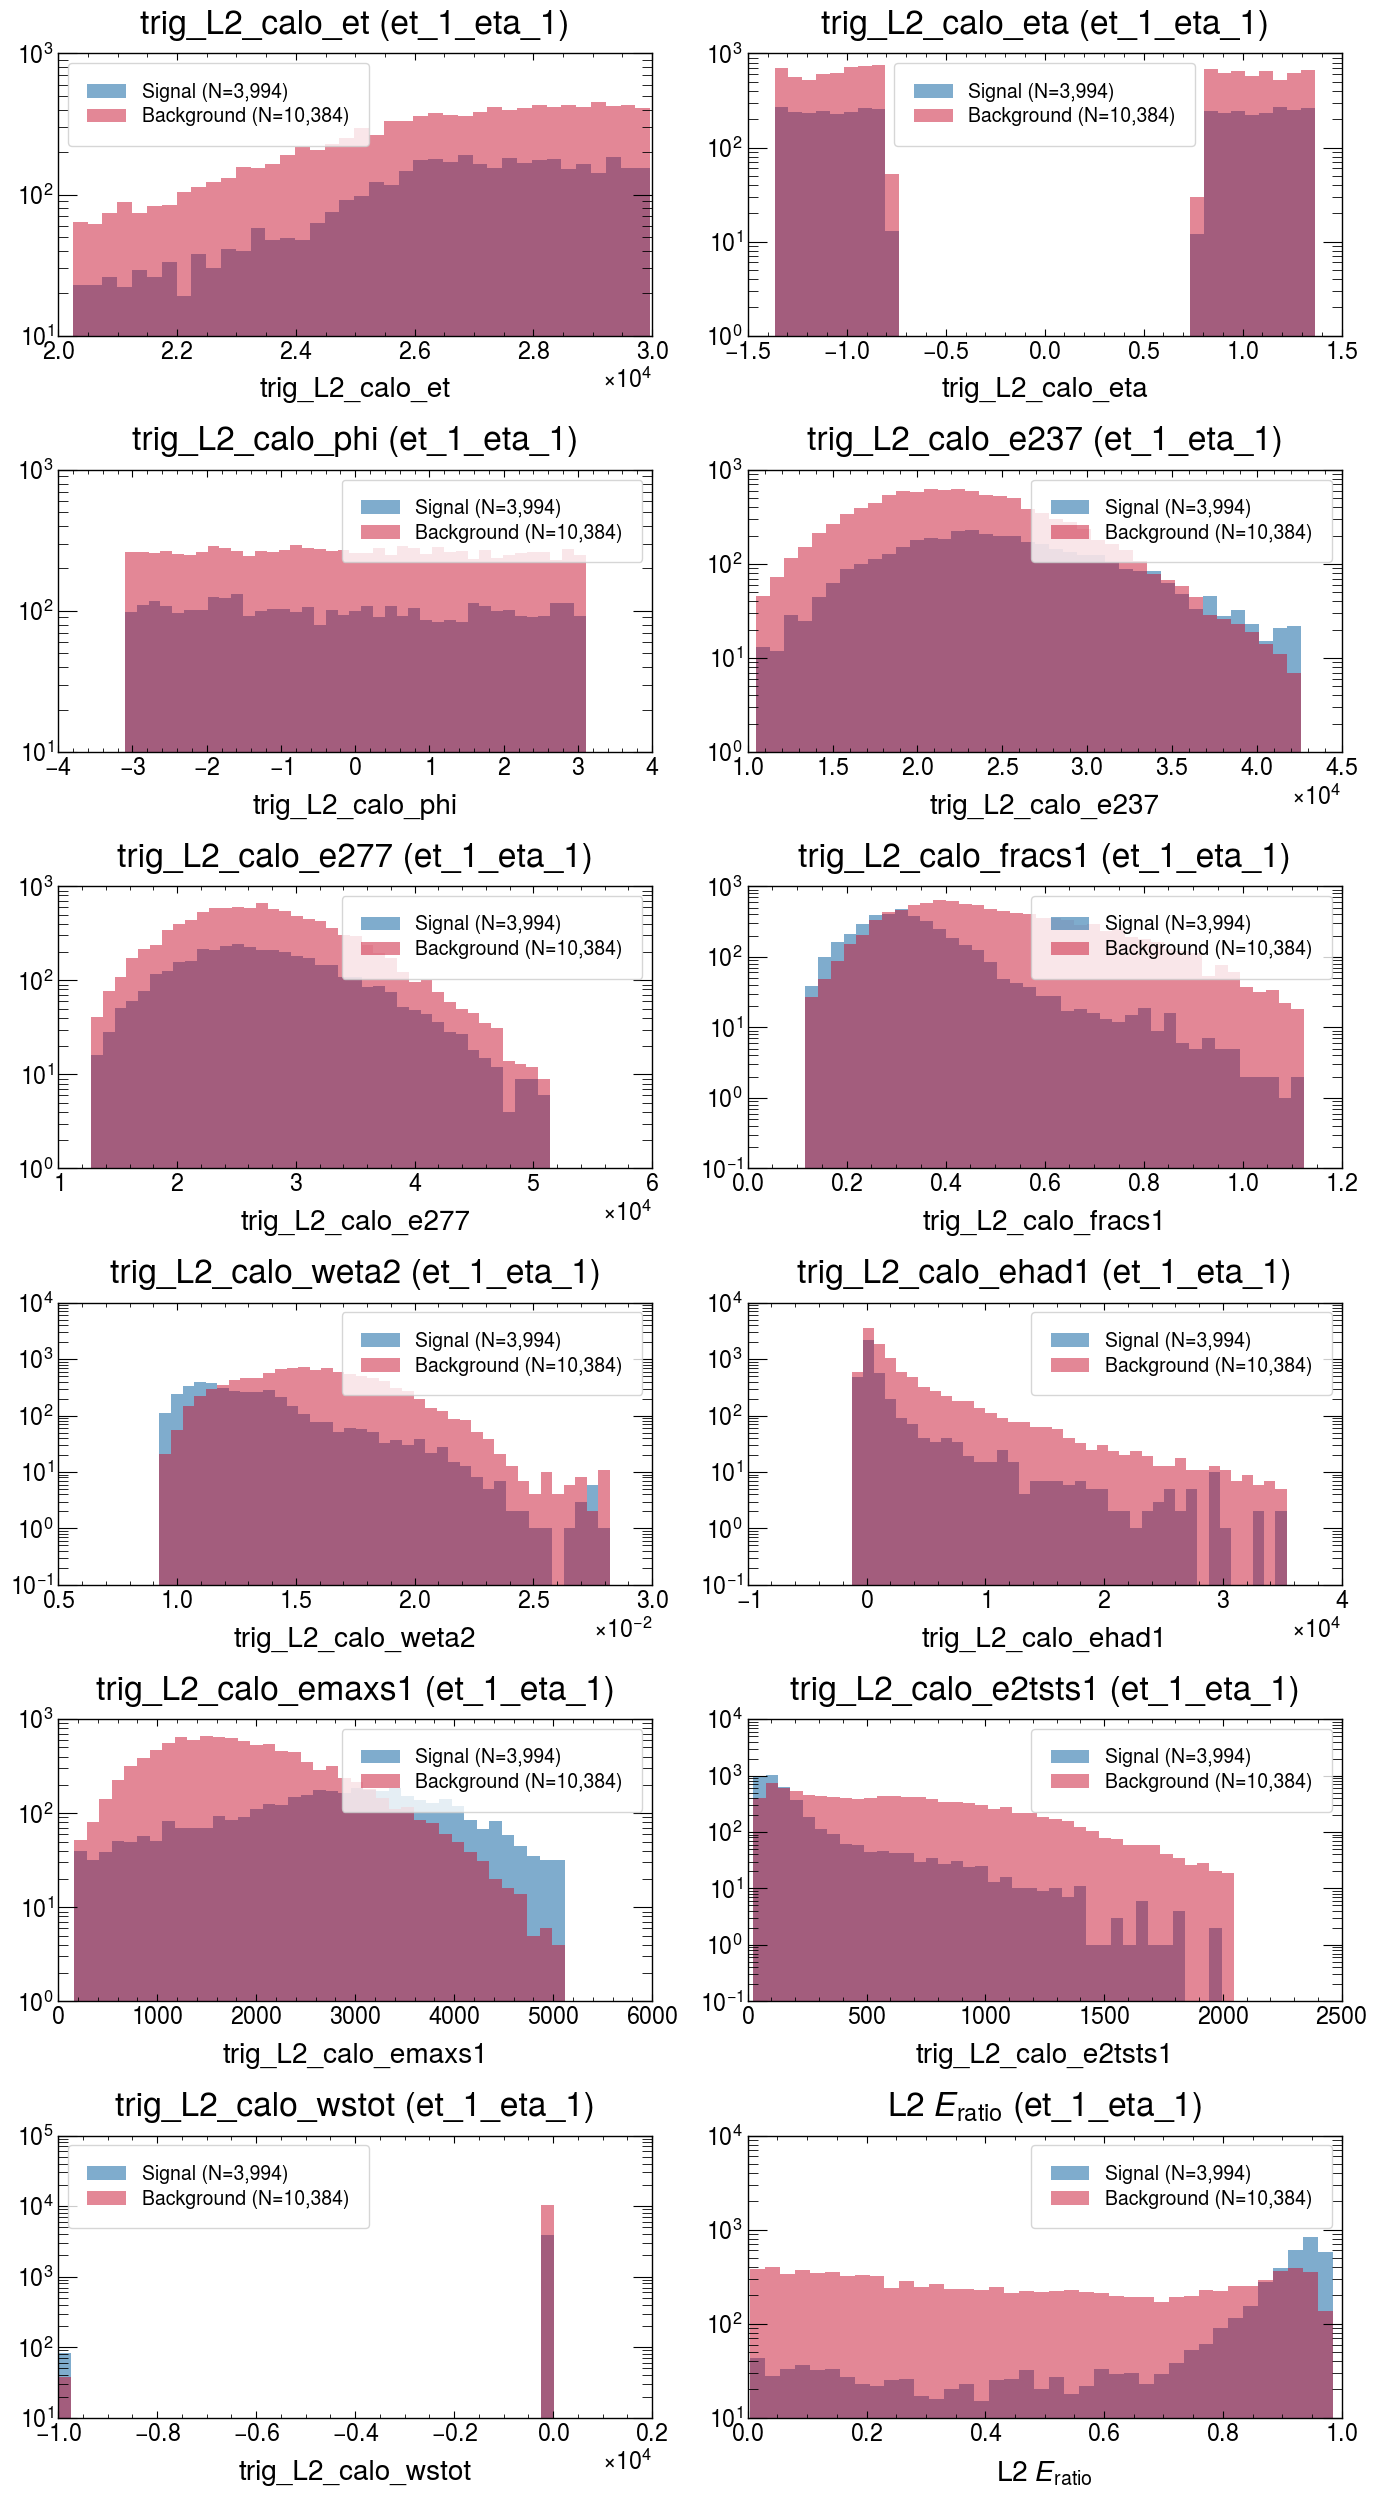

In [4]:
feature_names = full_dataset.feature_names

# Validate configured features
valid_features_to_plot = []
for f in FEATURES_TO_PLOT:
    try:
        _ = extract_feature_values(test_features[:5], feature_names, f)
        valid_features_to_plot.append(f)
    except KeyError as e:
        print(f"Skipping {f}: {e}")

feature_plots_dir = TRUE_DATA_PLOTS_DIR
feature_plots_dir.mkdir(parents=True, exist_ok=True)

n_features = len(valid_features_to_plot)
cols = 2
rows = (n_features + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, 4.2 * rows))
axes = np.array(axes).reshape(-1)

for idx, feat_name in enumerate(valid_features_to_plot):
    ax = axes[idx]
    values = extract_feature_values(test_features, feature_names, feat_name)

    val_sig = values[test_labels == 1]
    val_bg = values[test_labels == 0]

    val_sig = val_sig[np.isfinite(val_sig)]
    val_bg = val_bg[np.isfinite(val_bg)]

    all_vals = np.concatenate([val_sig, val_bg])
    low, high = np.percentile(all_vals, 0.5), np.percentile(all_vals, 99.5)
    bins = np.linspace(low, high, 40)

    ax.hist(val_sig, bins=bins, density=False, alpha=0.5, color="#005A9C", label=f"Signal (N={len(val_sig):,})")
    ax.hist(val_bg, bins=bins, density=False, alpha=0.5, color="#C8102E", label=f"Background (N={len(val_bg):,})")

    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name
    ax.set_title(f"{display_title} ({REGION_KEY})", pad=14)
    ax.set_xlabel(display_title, loc="center")
    ax.set_yscale('log')
    ax.legend(frameon=True)

    fig_single, ax_single = plt.subplots(figsize=(7, 4.8))
    ax_single.hist(val_sig, bins=bins, density=False, alpha=0.5, color="#005A9C", label=f"Signal (N={len(val_sig):,})")
    ax_single.hist(val_bg, bins=bins, density=False, alpha=0.5, color="#C8102E", label=f"Background (N={len(val_bg):,})")
    ax_single.set_title(f"{display_title} ({REGION_KEY})", pad=14)
    ax_single.set_xlabel(display_title, loc="center")
    ax_single.legend(frameon=True)
    fig_single.tight_layout()
    fig_single.savefig(
        feature_plots_dir / f"{feat_name}_distribution.{PLOT_FORMAT}",
        format=PLOT_FORMAT,
        transparent=False,
        bbox_inches="tight",
    )
    plt.close(fig_single)

# Remove unused subplots if odd number
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### 3. Model 1 Training Curves & Metric Evaluation
Scans fold files using [`ResultAggregator`](file:///home/pmourafr/egamma_master/src/core/Validation/ResultAggregator.py), extracts best SP checkpoint, and generates metric plots:



In [5]:
metrics_out_dir = OUTPUT_DIR / "Metrics_Model1"
metrics_out_dir.mkdir(parents=True, exist_ok=True)

aggregator_1 = ResultAggregator(RESULTS_PATH_1)
if not aggregator_1.has_region(TARGET_ET, TARGET_ETA):
    raise RuntimeError(f"No result records found in {RESULTS_PATH_1} for iet{TARGET_ET}.ieta{TARGET_ETA}")

best_model_1, best_rep_1, mean_sp_1, std_sp_1 = aggregator_1.get_best_model_for_region(TARGET_ET, TARGET_ETA)
print(f"Model 1 Best SP for {REGION_KEY}: {best_model_1['best_sp_value']:.4f} (Region Mean: {mean_sp_1:.4f} ± {std_sp_1:.4f})")
print(f"Best Fold: {best_model_1.get('fold')}, Best Init: {best_rep_1}")

# Generate training curves via PlotManager
plot_manager = PlotManager()
grouped_results_1 = aggregator_1.group_and_concat()
region_group_key = f"iet{TARGET_ET}.ieta{TARGET_ETA}"
df_region_1 = grouped_results_1.get(region_group_key)

if df_region_1 is not None and not df_region_1.empty:
    plot_manager.run_metrics_for_region(df_region_1, str(metrics_out_dir), TARGET_ET, TARGET_ETA)
    print(f"Generated metric figures saved under: {metrics_out_dir}")


Model 1 Best SP for et_1_eta_1: 0.8464 (Region Mean: 0.8423 ± 0.0039)
Best Fold: 6, Best Init: 3


Generated metric figures saved under: /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261029001623/Metrics_Model1


### 4. Model 1 Efficiency Validation & Operational Response Curves
Evaluates the best checkpoint weights on the holdout test set using [`HoldoutEvaluator`](file:///home/pmourafr/egamma_master/src/core/Validation/HoldoutEvaluator.py) and [`EfficiencyPlotter`](file:///home/pmourafr/egamma_master/src/core/Validation/EfficiencyPlotter.py):



In [6]:
validation_out_dir = OUTPUT_DIR / "Validation_Model1"
validation_out_dir.mkdir(parents=True, exist_ok=True)

model_1 = trainer_1.factory.create_model()
model_1.load_state_dict(best_model_1["best_weights"])
model_1.to(trainer_1.device)
model_1.eval()

evaluator = HoldoutEvaluator(default_target_pd=TARGET_PD)

ring_column_indices = full_dataset.ring_column_indices
if ring_column_indices is None:
    ring_column_indices = full_dataset.indexes

eval_result_1 = evaluator.evaluate(
    model=model_1,
    data=raw_features,
    target=raw_labels,
    test_indices=test_indices,
    ring_column_indices=ring_column_indices,
    device=trainer_1.device,
    target_pd=TARGET_PD,
)

print(f"Validation Holdout Performance for Model 1 ({REGION_KEY}):")
print(f"  Target Detection Efficiency (PD):   {eval_result_1.pd:.4f} ({eval_result_1.pd:.2%})")
print(f"  Calibrated Operating Cut (Th):       {eval_result_1.threshold:.4f}")
print(f"  False Alarm Rate (PF):               {eval_result_1.pf:.4f} ({eval_result_1.pf:.2%})")
print(f"  SP Index at Target Cut:              {eval_result_1.sp:.4f}")
print(f"  Area Under ROC Curve (AUC):          {eval_result_1.auc:.4f}")

# Render efficiency curves
eta_idx = int(np.where(feature_names == "trig_L2_calo_eta")[0][0])
et_idx = int(np.where(feature_names == "trig_L2_calo_et")[0][0])
eff_plotter = EfficiencyPlotter(et_idx, eta_idx)

eff_plotter.plot_regional_efficiency(
    result=eval_result_1,
    iet=TARGET_ET,
    ieta=TARGET_ETA,
    plot_dir=validation_out_dir,
    config_name=config_1.config_name,
)
print(f"Efficiency validation plots saved to: {validation_out_dir}")


Validation Holdout Performance for Model 1 (et_1_eta_1):
  Target Detection Efficiency (PD):   0.9424 (94.24%)
  Calibrated Operating Cut (Th):       0.0728
  False Alarm Rate (PF):               0.4704 (47.04%)
  SP Index at Target Cut:              0.7211
  Area Under ROC Curve (AUC):          0.9018
Efficiency validation plots saved to: /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261029001623/Validation_Model1


#### Model 1 Operating Points & Efficiency Table with Uncertainties
Consolidates operational metrics (Detection Efficiency, False Alarm, Background Rejection, Accuracy, and SP index) with binomial and error-propagated uncertainties for both default (0.5) and calibrated ($Th_{\text{target}}$) threshold cuts:


In [7]:
m_def = StrategyMetrics.from_predictions(eval_result_1.predictions_default_threshold, eval_result_1.holdout_labels)
m_cal = StrategyMetrics.from_predictions(eval_result_1.predictions_calibrated_cut, eval_result_1.holdout_labels)

efficiency_table = pd.DataFrame([
    {
        "Operating Point": "Default Threshold (0.5000)",
        "Decision Threshold": 0.5000,
        "PD (Signal Eff)": m_def.pd,
        "PD Uncertainty": m_def.pd_uncertainty,
        "PF (Fake Rate)": m_def.pf,
        "PF Uncertainty": m_def.pf_uncertainty,
        "Background Rejection": m_def.bg_eff,
        "Background Rejection Uncertainty": m_def.bg_eff_uncertainty,
        "Accuracy (Eff)": m_def.eff,
        "Accuracy Uncertainty": m_def.eff_uncertainty,
        "SP Index": m_def.sp,
        "SP Index Uncertainty": m_def.sp_uncertainty,
        "TP": m_def.tp,
        "FP": m_def.fp,
        "TN": m_def.tn,
        "FN": m_def.fn,
    },
    {
        "Operating Point": f"Calibrated Cut (Target PD: {TARGET_PD*100:.2f}%)",
        "Decision Threshold": eval_result_1.threshold,
        "PD (Signal Eff)": m_cal.pd,
        "PD Uncertainty": m_cal.pd_uncertainty,
        "PF (Fake Rate)": m_cal.pf,
        "PF Uncertainty": m_cal.pf_uncertainty,
        "Background Rejection": m_cal.bg_eff,
        "Background Rejection Uncertainty": m_cal.bg_eff_uncertainty,
        "Accuracy (Eff)": m_cal.eff,
        "Accuracy Uncertainty": m_cal.eff_uncertainty,
        "SP Index": m_cal.sp,
        "SP Index Uncertainty": m_cal.sp_uncertainty,
        "TP": m_cal.tp,
        "FP": m_cal.fp,
        "TN": m_cal.tn,
        "FN": m_cal.fn,
    },
])
display(efficiency_table)
save_table(efficiency_table, TABLES_DIR, REGION_KEY, "operating_points_efficiency")

,Operating Point,Decision Threshold,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,Background Rejection,Background Rejection Uncertainty,Accuracy (Eff),Accuracy Uncertainty,SP Index,SP Index Uncertainty,TP,FP,TN,FN
0,Default Threshold (0.5000),0.500000,0.674512,0.007414,0.060381,0.002337,0.939619,0.002337,0.865976,0.002841,0.801567,0.004185,2694,627,9757,1300
1,Calibrated Cut (Target PD: 94.24%),0.072817,0.942414,0.003686,0.470435,0.004898,0.529565,0.004898,0.644248,0.003993,0.721067,0.003287,3764,4885,5499,230


PosixPath('/eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261029001623/Tables/et_1_eta_1_operating_points_efficiency.csv')

### 5. Quadrant Analysis: Model 1 vs Athena Trigger Linear Cuts
Compares predictions against the cut-based baseline using [`QuadrantAnalyzer`](file:///home/pmourafr/egamma_master/src/core/Validation/QuadrantAnalyzer.py) in `model_vs_cut` mode:



In [8]:
quadrant_cut_dir = OUTPUT_DIR / "Quadrant_Model_vs_Cut"
quadrant_cut_dir.mkdir(parents=True, exist_ok=True)

quadrant_cut_analyzer = QuadrantAnalyzer(
    config_path1=str(CONFIG_PATH_1),
    data_path1=str(RESULTS_PATH_1),
    manifest_path=str(MANIFEST_PATH),
    threshold_mode=THRESHOLD_MODE,
    efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
    default_target_pd=TARGET_PD,
    mode="model_vs_cut",
    working_point=WORKING_POINT,
    target_et=TARGET_ET,
    target_eta=TARGET_ETA,
    strategy1_alias=MODEL_1_ALIAS,
    strategy2_alias=ATHENA_ALIAS,
)

cut_results = quadrant_cut_analyzer.run()
if not cut_results:
    raise RuntimeError(f"No quadrant results generated for {REGION_KEY}")

cut_res = cut_results[0]
s1 = cut_res.metrics_strategy1
s2 = cut_res.metrics_strategy2
qm = cut_res.overall_metrics

comparison_table = pd.DataFrame([
    {
        "Strategy": cut_res.strategy1_name,
        "PD (Signal Eff)": s1.pd,
        "PD Uncertainty": s1.pd_uncertainty,
        "PF (Fake Rate)": s1.pf,
        "PF Uncertainty": s1.pf_uncertainty,
        "SP Index": s1.sp,
        "SP Index Uncertainty": s1.sp_uncertainty,
        "Accuracy": s1.eff,
        "Accuracy Uncertainty": s1.eff_uncertainty,
    },
    {
        "Strategy": cut_res.strategy2_name,
        "PD (Signal Eff)": s2.pd,
        "PD Uncertainty": s2.pd_uncertainty,
        "PF (Fake Rate)": s2.pf,
        "PF Uncertainty": s2.pf_uncertainty,
        "SP Index": s2.sp,
        "SP Index Uncertainty": s2.sp_uncertainty,
        "Accuracy": s2.eff,
        "Accuracy Uncertainty": s2.eff_uncertainty,
    }
])
display(comparison_table)
save_table(comparison_table, TABLES_DIR, REGION_KEY, f"model1_vs_cut_{WORKING_POINT}_strategy_metrics")

quadrant_counts = pd.DataFrame({
    "Quadrant": [
        "Both Correct",
        f"Only {cut_res.strategy1_name} Correct",
        f"Only {cut_res.strategy2_name} Correct",
        "Both Wrong"
    ],
    "Event Count": [qm.both_correct, qm.model1_only_correct, qm.model2_only_correct, qm.both_wrong],
    "Ratio": [f"{qm.both_correct_ratio:.2%}", f"{qm.model1_only_correct_ratio:.2%}", f"{qm.model2_only_correct_ratio:.2%}", f"{qm.both_wrong_ratio:.2%}"]
})
print(f"McNemar p-value: {qm.mcnemar_p_value:.3e}")
display(quadrant_counts)
save_table(quadrant_counts, TABLES_DIR, REGION_KEY, f"model1_vs_cut_{WORKING_POINT}_quadrant_counts")

# Render standard quadrant figures
quadrant_plotter = QuadrantPlotter()
saved_cut_plots = quadrant_plotter.plot([cut_res], quadrant_cut_dir, file_format=PLOT_FORMAT)
print(f"Generated {sum(len(p) for p in saved_cut_plots.values())} quadrant plots under: {quadrant_cut_dir}")


,Strategy,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,SP Index,SP Index Uncertainty,Accuracy,Accuracy Uncertainty
0,Model V9 (100 Rings),0.942414,0.003686,0.470435,0.004898,0.721067,0.003287,0.644248,0.003993
1,Athena Loose Cut,0.777666,0.006580,0.414965,0.004835,0.677921,0.004026,0.638545,0.004007


McNemar p-value: 2.803e-01


,Quadrant,Event Count,Ratio
0,Both Correct,6408,44.57%
1,Only Model V9 (100 Rings) Correct,2855,19.86%
2,Only Athena Loose Cut Correct,2773,19.29%
3,Both Wrong,2342,16.29%


Generated 13 quadrant plots under: /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261029001623/Quadrant_Model_vs_Cut


### 6. Signal & Background Feature Distributions by Model
Compares true class distributions against event selections for all models found across all mapped features:
- **Plot 1 (Signal Events)**: True Signal events shown with black dots (without error bars); ML model selections shown with full (filled) symbols with Poisson error bars; Athena Linear Cut selections shown with open (not full) symbols with Poisson error bars.
- **Plot 2 (Background Events)**: True Background events shown with black dots (without error bars); ML model selections shown with full (filled) symbols with Poisson error bars; Athena Linear Cut selections shown with open (not full) symbols with Poisson error bars.


#### Models to plot

In [9]:
models_to_plot = [
    {
        "name": MODEL_1_ALIAS,
        "preds": cut_res.preds_strategy1,
        "is_ml": True,
        "color": "#005A9C",
        "marker": "s",
    },
    {
        "name": ATHENA_ALIAS,
        "preds": cut_res.preds_strategy2,
        "is_ml": False,
        "color": "#E65100",
        "marker": "o",
    },
]


In [10]:
if ENABLE_MODEL2_COMPARISON and RESULTS_PATH_2.exists():
    try:
        aggregator_2 = ResultAggregator(RESULTS_PATH_2)
        if aggregator_2.has_region(TARGET_ET, TARGET_ETA):
            best_model_2, _, _, _ = aggregator_2.get_best_model_for_region(TARGET_ET, TARGET_ETA)
            with open(CONFIG_PATH_2, "r") as f2:
                config_dict_2 = yaml.safe_load(f2)
            if DATA_PATH.exists():
                config_dict_2["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)
            config_2 = NeuralRingerTrainerConfiguration.model_validate(config_dict_2)
            trainer_2 = NeuralRingerTrainer(config_2)

            # Locate dataset index in Model 2 matching TARGET_ET and TARGET_ETA
            region_file_idx_2 = None
            for idx_f, path_str in enumerate(trainer_2.full_dataset.file_paths):
                iet_f, ieta_f = get_et_eta(path_str)
                if iet_f == TARGET_ET and ieta_f == TARGET_ETA:
                    region_file_idx_2 = idx_f
                    break

            if region_file_idx_2 is not None:
                data_2, target_2, _ = trainer_2.full_dataset[region_file_idx_2]
                ring_indices_2 = trainer_2.full_dataset.ring_column_indices

                model_2 = trainer_2.factory.create_model()
                model_2.load_state_dict(best_model_2["best_weights"])
                model_2.to(trainer_1.device)
                model_2.eval()

                eval_res_2 = evaluator.evaluate(
                    model=model_2,
                    data=data_2,
                    target=target_2,
                    test_indices=test_indices,
                    ring_column_indices=ring_indices_2,
                    device=trainer_1.device,
                    target_pd=TARGET_PD,
                )
                preds_2 = (
                    eval_res_2.predictions_calibrated_cut
                    if THRESHOLD_MODE == "calibrated"
                    else eval_res_2.predictions_default_threshold
                )
                models_to_plot.append({
                    "name": MODEL_2_ALIAS,
                    "preds": preds_2,
                    "is_ml": True,
                    "color": "#2E7D32",
                    "marker": "^",
                })
    except Exception as e:
        print(f"Note: Model 2 predictions not added: {e}")


### 6.1 Distribution Distance Precomputations (KS, Wasserstein, KL & JS Divergences)
Precomputes binned histogram distributions for plotting and evaluates statistical distance metrics (KS test, Wasserstein distance, KL divergence, and JS divergence) with bootstrap uncertainties across multiple reference baselines:
1. **Model vs. True Data** (evaluation against physical ground-truth population)
2. **Model vs. Athena Cut** (evaluation against benchmark trigger selection)
3. **Model 1 vs. Model 2** (direct cross-architecture evaluation)

In [11]:
print("Precomputing feature distributions, Poisson uncertainties, and multi-reference distance metrics...")

signal_plot_data = {}
background_plot_data = {}

for feat_name in valid_features_to_plot:
    values = extract_feature_values(test_features, feature_names, feat_name)
    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name

    # 1. Signal Histogram Precomputations
    val_true_sig = values[test_labels == 1]
    val_true_sig = val_true_sig[np.isfinite(val_true_sig)]

    low_sig = np.percentile(val_true_sig, 0.5)
    high_sig = np.percentile(val_true_sig, 99.5)
    bins_sig = np.linspace(low_sig, high_sig, 35)
    bin_centers_sig = 0.5 * (bins_sig[:-1] + bins_sig[1:])

    counts_true_sig, _ = np.histogram(val_true_sig, bins=bins_sig)

    model_sig_data = []
    for m in models_to_plot:
        val_m_sig = values[(test_labels == 1) & (m["preds"] == 1)]
        val_m_sig = val_m_sig[np.isfinite(val_m_sig)]
        counts_m_sig, _ = np.histogram(val_m_sig, bins=bins_sig)
        err_m_sig = np.sqrt(counts_m_sig)

        model_sig_data.append({
            "name": m["name"],
            "counts": counts_m_sig,
            "errors": err_m_sig,
            "is_ml": m["is_ml"],
            "color": m["color"],
            "marker": m["marker"],
            "label": m["name"],
        })

    signal_plot_data[feat_name] = {
        "display_title": display_title,
        "bin_centers": bin_centers_sig,
        "true_counts": counts_true_sig,
        "true_n": len(val_true_sig),
        "models": model_sig_data,
    }

    # 2. Background Histogram Precomputations
    val_true_bg = values[test_labels == 0]
    val_true_bg = val_true_bg[np.isfinite(val_true_bg)]

    low_bg = np.percentile(val_true_bg, 0.5)
    high_bg = np.percentile(val_true_bg, 99.5)
    bins_bg = np.linspace(low_bg, high_bg, 35)
    bin_centers_bg = 0.5 * (bins_bg[:-1] + bins_bg[1:])

    counts_true_bg, _ = np.histogram(val_true_bg, bins=bins_bg)

    model_bg_data = []
    for m in models_to_plot:
        val_m_bg = values[(test_labels == 0) & (m["preds"] == 1)]
        val_m_bg = val_m_bg[np.isfinite(val_m_bg)]
        counts_m_bg, _ = np.histogram(val_m_bg, bins=bins_bg)
        err_m_bg = np.sqrt(counts_m_bg)

        model_bg_data.append({
            "name": m["name"],
            "counts": counts_m_bg,
            "errors": err_m_bg,
            "is_ml": m["is_ml"],
            "color": m["color"],
            "marker": m["marker"],
            "label": m["name"],
        })

    background_plot_data[feat_name] = {
        "display_title": display_title,
        "bin_centers": bin_centers_bg,
        "true_counts": counts_true_bg,
        "true_n": len(val_true_bg),
        "models": model_bg_data,
    }

# 3. Statistical Distance Evaluation across References (True Data, Athena Cut, Model vs Model)
dist_comparator = DistributionComparator(n_bootstraps=100, random_seed=42)
strategies_dict = {m["name"]: m["preds"] for m in models_to_plot}

# A. Comparisons vs True Data
sig_ks_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict, reference_strategy=None, is_signal=True
)
bg_ks_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict, reference_strategy=None, is_signal=False
)

# B. Comparisons vs Athena Trigger Cut
athena_name = cut_res.strategy2_name
sig_vs_athena_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict, reference_strategy=athena_name, is_signal=True
)
bg_vs_athena_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict, reference_strategy=athena_name, is_signal=False
)

# C. Model vs Model (if secondary model is loaded)
secondary_ml_models = [m["name"] for m in models_to_plot if m["is_ml"] and m["name"] != cut_res.strategy1_name]
if secondary_ml_models:
    ref_m2 = secondary_ml_models[0]
    sig_m1_vs_m2_df = dist_comparator.compare_strategies(
        test_features, feature_names, test_labels, valid_features_to_plot,
        strategies_dict, reference_strategy=ref_m2, is_signal=True
    )
    bg_m1_vs_m2_df = dist_comparator.compare_strategies(
        test_features, feature_names, test_labels, valid_features_to_plot,
        strategies_dict, reference_strategy=ref_m2, is_signal=False
    )
else:
    sig_m1_vs_m2_df = pd.DataFrame()
    bg_m1_vs_m2_df = pd.DataFrame()


Precomputing feature distributions, Poisson uncertainties, and multi-reference distance metrics...


/cvmfs/sft.cern.ch/lcg/views/LCG_109_cuda/x86_64-el9-gcc13-opt/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  res = hypotest_fun_out(*samples, **kwds)


In [12]:
# 1. True Signal Comparison Table
if not sig_ks_df.empty:
    print(f"Distance Metrics vs True Signal (Photons) ({REGION_KEY}):")
    display(sig_ks_df)
    save_table(sig_ks_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_true_signal")

# 2. Athena Cut Comparison Table
if not sig_vs_athena_df.empty:
    print(f"\nDistance Metrics vs Athena Cut ({athena_name}) - Signal ({REGION_KEY}):")
    display(sig_vs_athena_df)
    save_table(sig_vs_athena_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_athena_cut_signal")

# 3. Model 1 vs Model 2 Comparison Table
if not sig_m1_vs_m2_df.empty:
    print(f"\nDistance Metrics: Model 1 vs Model 2 - Signal ({REGION_KEY}):")
    display(sig_m1_vs_m2_df)
    save_table(sig_m1_vs_m2_df, TABLES_DIR, REGION_KEY, "distance_metrics_model1_vs_model2_signal")


Distance Metrics vs True Signal (Photons) (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KS Distance (D),KS Uncertainty,Wasserstein Distance,Wasserstein Uncertainty,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty,p-value,Distribution Equality
0,trig_L2_calo_et,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3764,0.015433,0.007104,80.393155,35.061029,0.001545,0.002693,0.000537,0.000914,7.368820e-01,Consistent (p ≥ 0.05)
1,trig_L2_calo_et,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.049584,0.007816,260.956045,45.977729,0.013618,0.005744,0.004515,0.001753,3.549358e-04,Distinct (p < 0.05)
2,trig_L2_calo_et,True Signal,Model V9 (50 Rings),Model V9 (50 Rings) vs True Signal,3994,3764,0.016230,0.008457,82.830829,42.062820,0.001554,0.002962,0.000542,0.000991,6.784525e-01,Consistent (p ≥ 0.05)
3,trig_L2_calo_eta,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3764,0.003809,0.004668,0.004977,0.011664,0.000207,0.001559,0.000075,0.000552,1.000000e+00,Consistent (p ≥ 0.05)
4,trig_L2_calo_eta,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.015245,0.006818,0.026522,0.017414,0.002597,0.002715,0.000936,0.000969,8.037868e-01,Consistent (p ≥ 0.05)
5,trig_L2_calo_eta,True Signal,Model V9 (50 Rings),Model V9 (50 Rings) vs True Signal,3994,3764,0.003809,0.005348,0.004989,0.012386,0.000185,0.001573,0.000067,0.000568,1.000000e+00,Consistent (p ≥ 0.05)
6,trig_L2_calo_phi,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3764,0.002662,0.005200,0.007052,0.017561,0.000308,0.002089,0.000110,0.000745,1.000000e+00,Consistent (p ≥ 0.05)
7,trig_L2_calo_phi,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.006741,0.006429,0.014681,0.020749,0.001909,0.002916,0.000688,0.001032,9.999973e-01,Consistent (p ≥ 0.05)
8,trig_L2_calo_phi,True Signal,Model V9 (50 Rings),Model V9 (50 Rings) vs True Signal,3994,3764,0.002689,0.005784,0.005626,0.019220,0.000217,0.002493,0.000078,0.000895,1.000000e+00,Consistent (p ≥ 0.05)
9,trig_L2_calo_e237,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3764,0.018580,0.009566,245.310525,122.086896,0.000995,0.002367,0.000355,0.000842,5.071732e-01,Consistent (p ≥ 0.05)



Distance Metrics vs Athena Cut (Athena Loose Cut) - Signal (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KS Distance (D),KS Uncertainty,Wasserstein Distance,Wasserstein Uncertainty,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty,p-value,Distribution Equality
0,trig_L2_calo_et,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,3106,3764,0.034675,0.008259,181.080414,45.133172,0.006462,0.003574,2.449132e-03,0.001388,3.239943e-02,Distinct (p < 0.05)
1,trig_L2_calo_et,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,3106,3764,0.034105,0.007891,178.566893,43.676792,0.006367,0.003384,2.419724e-03,0.001293,3.704398e-02,Distinct (p < 0.05)
2,trig_L2_calo_eta,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,3106,3764,0.017402,0.006783,0.022977,0.015759,0.002762,0.002544,9.977404e-04,0.000913,6.724671e-01,Consistent (p ≥ 0.05)
3,trig_L2_calo_eta,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,3106,3764,0.017933,0.005822,0.023234,0.016292,0.002844,0.002390,1.027712e-03,0.000861,6.355053e-01,Consistent (p ≥ 0.05)
4,trig_L2_calo_phi,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,3106,3764,0.005723,0.006247,0.013968,0.020691,0.001877,0.002535,6.779106e-04,0.000921,1.000000e+00,Consistent (p ≥ 0.05)
5,trig_L2_calo_phi,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,3106,3764,0.005664,0.006703,0.013069,0.021898,0.001775,0.002709,6.399829e-04,0.000989,1.000000e+00,Consistent (p ≥ 0.05)
6,trig_L2_calo_e237,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,3106,3764,0.020184,0.007871,231.398678,99.212688,0.001942,0.002757,7.104820e-04,0.001044,4.838726e-01,Consistent (p ≥ 0.05)
7,trig_L2_calo_e237,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,3106,3764,0.019653,0.007793,220.170112,115.354596,0.001716,0.002872,6.275099e-04,0.001051,5.183664e-01,Consistent (p ≥ 0.05)
8,trig_L2_calo_e277,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,3106,3764,0.044825,0.009954,813.276850,177.821218,0.006564,0.004043,2.446269e-03,0.001543,2.058107e-03,Distinct (p < 0.05)
9,trig_L2_calo_e277,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,3106,3764,0.044559,0.010820,839.229559,184.357088,0.006855,0.004107,2.552693e-03,0.001534,2.231970e-03,Distinct (p < 0.05)



Distance Metrics: Model 1 vs Model 2 - Signal (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KS Distance (D),KS Uncertainty,Wasserstein Distance,Wasserstein Uncertainty,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty,p-value,Distribution Equality
0,trig_L2_calo_et,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),3764,3764,0.001063,0.006176,3.809594,22.299096,0.000127,0.002240,4.583173e-05,0.000796,1.000000e+00,Consistent (p ≥ 0.05)
1,trig_L2_calo_et,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),3764,3106,0.034105,0.008294,178.566893,46.019641,0.007149,0.004261,2.419724e-03,0.001339,3.704398e-02,Distinct (p < 0.05)
2,trig_L2_calo_eta,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),3764,3764,0.001860,0.006047,0.000525,0.013528,0.000046,0.001458,1.644006e-05,0.000520,1.000000e+00,Consistent (p ≥ 0.05)
3,trig_L2_calo_eta,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),3764,3106,0.017933,0.007743,0.023234,0.018031,0.002857,0.002984,1.027712e-03,0.001061,6.355053e-01,Consistent (p ≥ 0.05)
4,trig_L2_calo_phi,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),3764,3764,0.002391,0.006752,0.005506,0.022950,0.000097,0.001898,3.498657e-05,0.000684,1.000000e+00,Consistent (p ≥ 0.05)
5,trig_L2_calo_phi,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),3764,3106,0.005664,0.006222,0.013069,0.019130,0.001775,0.002916,6.399829e-04,0.001039,1.000000e+00,Consistent (p ≥ 0.05)
6,trig_L2_calo_e237,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),3764,3764,0.001328,0.006053,15.653756,66.750860,0.000111,0.002302,4.020026e-05,0.000815,1.000000e+00,Consistent (p ≥ 0.05)
7,trig_L2_calo_e237,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),3764,3106,0.019653,0.007712,220.170112,91.990643,0.001768,0.002937,6.275099e-04,0.000990,5.183664e-01,Consistent (p ≥ 0.05)
8,trig_L2_calo_e277,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),3764,3764,0.003188,0.006083,29.009961,79.876695,0.000182,0.002211,6.577655e-05,0.000767,1.000000e+00,Consistent (p ≥ 0.05)
9,trig_L2_calo_e277,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),3764,3106,0.044559,0.010468,839.229559,169.819526,0.007359,0.007409,2.552693e-03,0.001508,2.231970e-03,Distinct (p < 0.05)


### 6.2 FIGURE 1: SIGNAL DISTRIBUTIONS (True Signal = Black Dots, Models = With Error Bars)


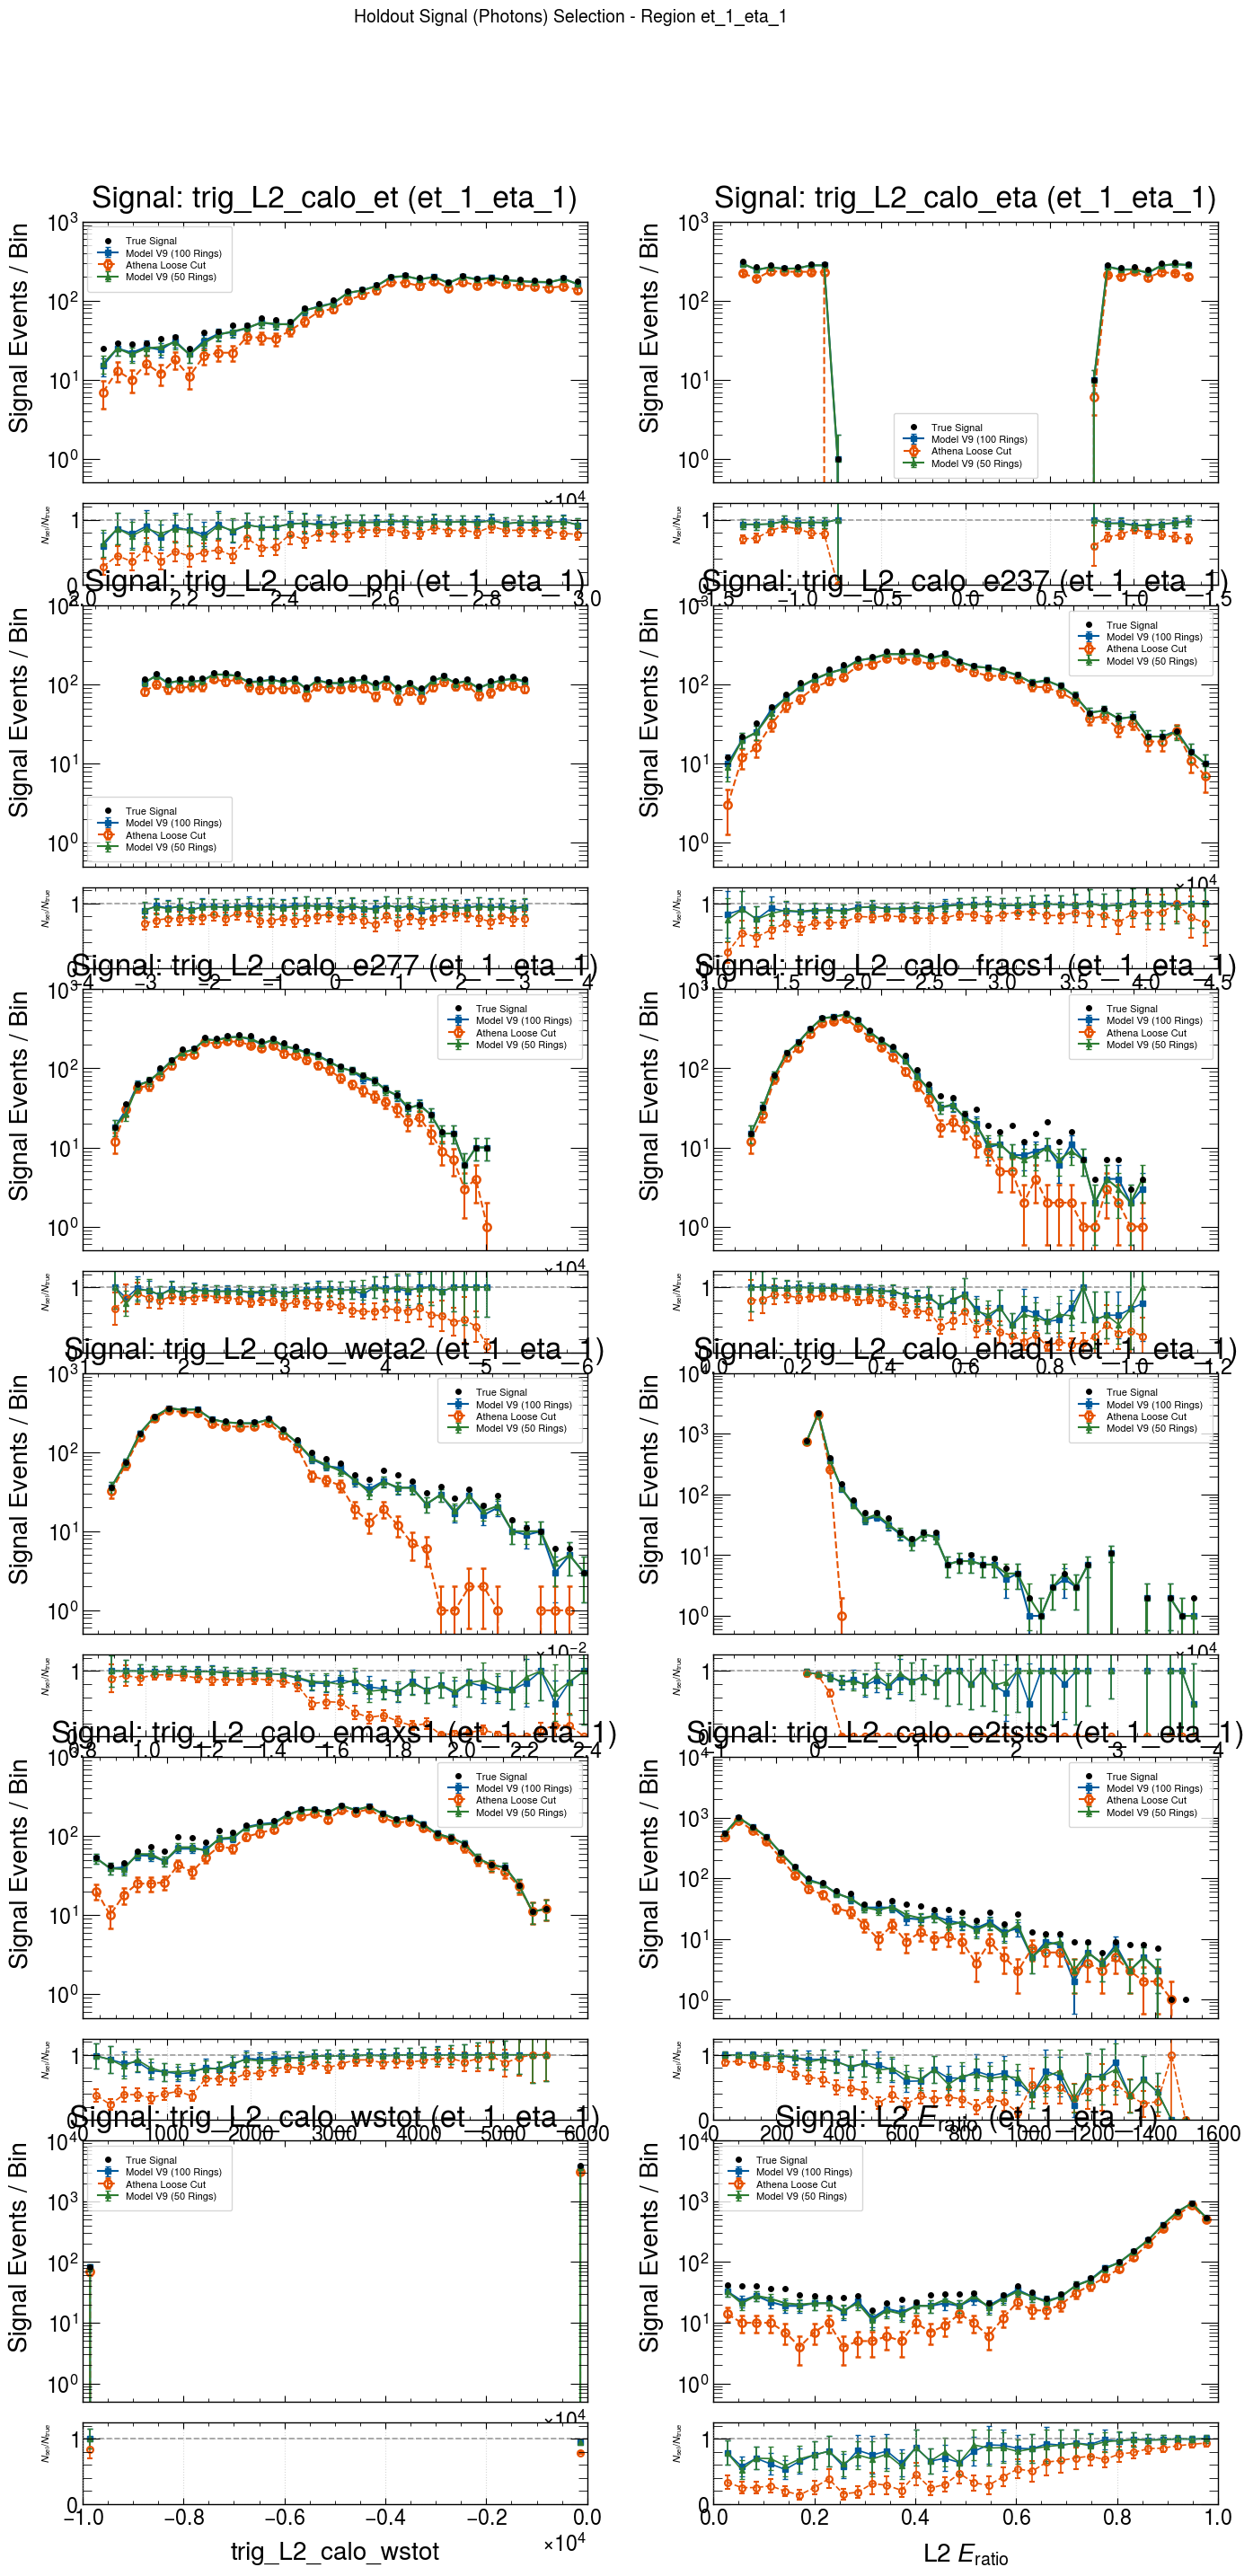

In [13]:
feature_plotter = FeatureDistributionPlotter()
fig_sig = feature_plotter.plot_and_export_all(
    plot_data=signal_plot_data,
    features_to_plot=valid_features_to_plot,
    output_dir=OUTPUT_DIR / "signal_selection",
    region_key=REGION_KEY,
    is_signal=True,
    log_y=True,
    plot_format=PLOT_FORMAT,
)
# plt.show()


### 6.3 FIGURE 2: BACKGROUND DISTRIBUTIONS (True Bg = Black Dots, Models = With Error Bars)


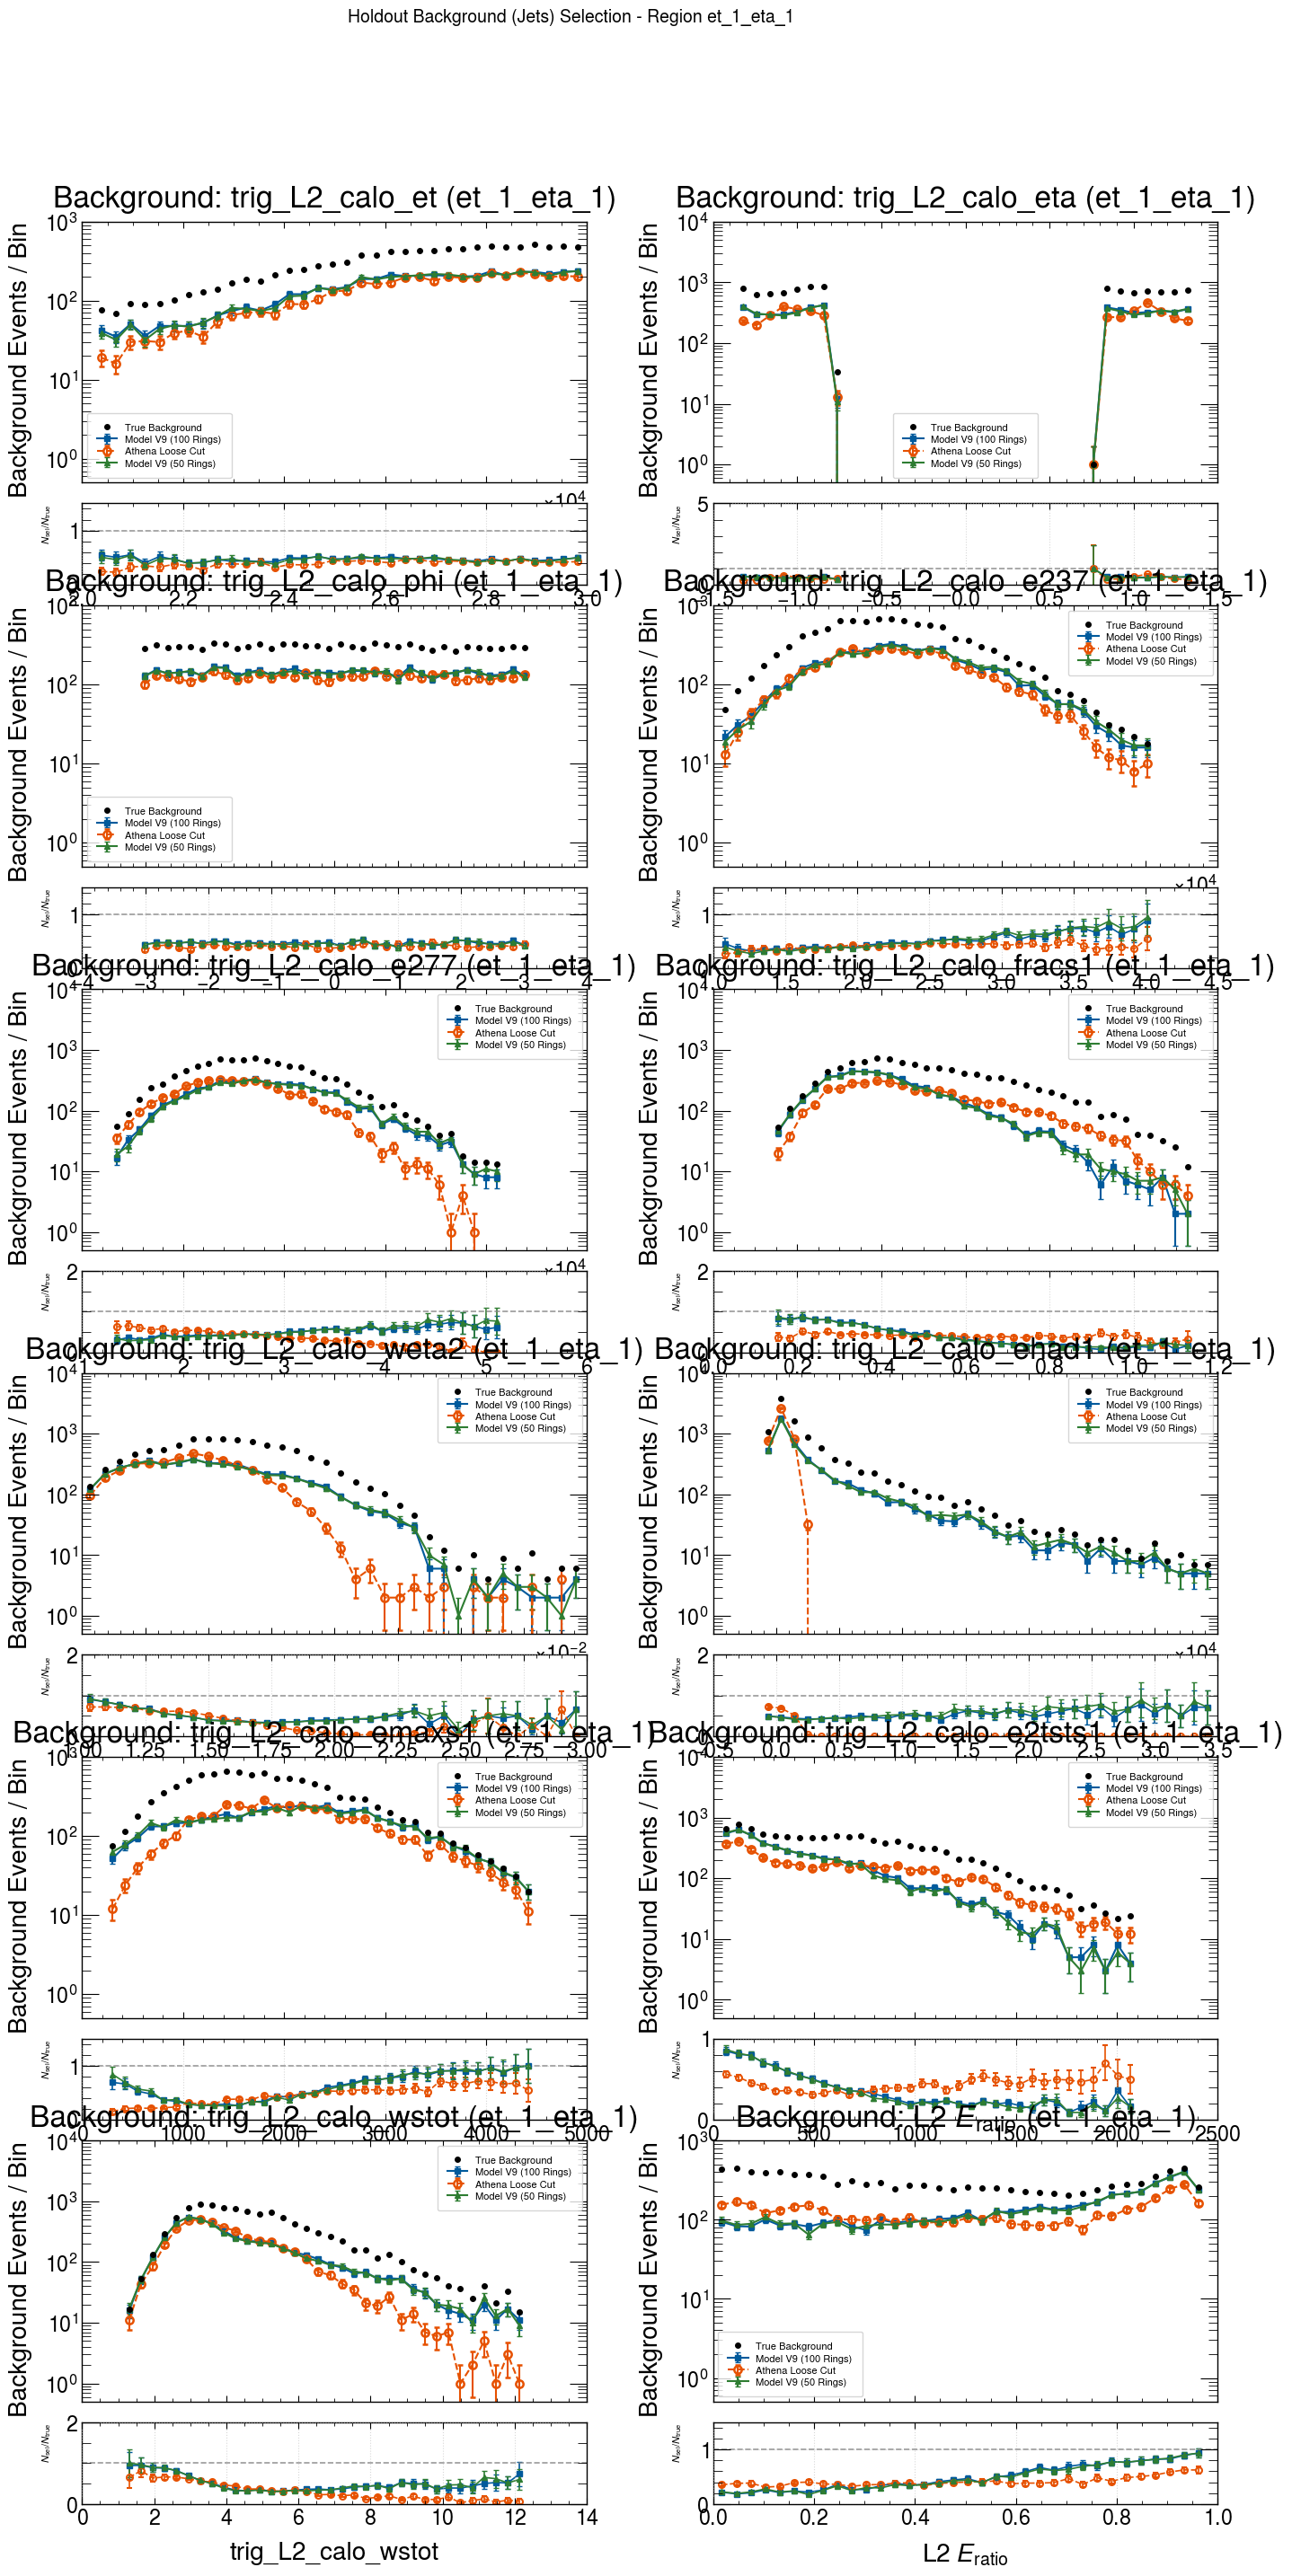

In [14]:
fig_bg = feature_plotter.plot_and_export_all(
    plot_data=background_plot_data,
    features_to_plot=valid_features_to_plot,
    output_dir=OUTPUT_DIR / "background_selection",
    region_key=REGION_KEY,
    is_signal=False,
    log_y=True,
    plot_format=PLOT_FORMAT,
)
# plt.show()


In [15]:
# 1. True Background Comparison Table
if not bg_ks_df.empty:
    print(f"Distance Metrics vs True Background (Jets) ({REGION_KEY}):")
    display(bg_ks_df)
    save_table(bg_ks_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_true_background")

# 2. Athena Cut Comparison Table (Background)
if not bg_vs_athena_df.empty:
    print(f"\nDistance Metrics vs Athena Cut ({athena_name}) - Background ({REGION_KEY}):")
    display(bg_vs_athena_df)
    save_table(bg_vs_athena_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_athena_cut_background")

# 3. Model 1 vs Model 2 Comparison Table (Background)
if not bg_m1_vs_m2_df.empty:
    print(f"\nDistance Metrics: Model 1 vs Model 2 - Background ({REGION_KEY}):")
    display(bg_m1_vs_m2_df)
    save_table(bg_m1_vs_m2_df, TABLES_DIR, REGION_KEY, "distance_metrics_model1_vs_model2_background")


Distance Metrics vs True Background (Jets) (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KS Distance (D),KS Uncertainty,Wasserstein Distance,Wasserstein Uncertainty,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty,p-value,Distribution Equality
0,trig_L2_calo_et,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,4885,0.011647,0.005535,34.047355,20.430746,0.002270,0.001889,0.000813,0.000671,7.537412e-01,Consistent (p ≥ 0.05)
1,trig_L2_calo_et,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.036222,0.006997,170.535108,36.979348,0.007262,0.002824,0.002486,0.000915,6.601972e-04,Distinct (p < 0.05)
2,trig_L2_calo_et,True Background,Model V9 (50 Rings),Model V9 (50 Rings) vs True Background,10384,4825,0.013839,0.004732,38.757172,16.163450,0.003068,0.002083,0.001099,0.000736,5.487829e-01,Consistent (p ≥ 0.05)
3,trig_L2_calo_eta,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,4885,0.015161,0.005685,0.020327,0.014286,0.001417,0.001128,0.000509,0.000406,4.256794e-01,Consistent (p ≥ 0.05)
4,trig_L2_calo_eta,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.042669,0.006294,0.051400,0.018047,0.030171,0.004279,0.010992,0.001552,2.962260e-05,Distinct (p < 0.05)
5,trig_L2_calo_eta,True Background,Model V9 (50 Rings),Model V9 (50 Rings) vs True Background,10384,4825,0.014549,0.004819,0.015618,0.010768,0.002461,0.001272,0.000885,0.000455,4.838923e-01,Consistent (p ≥ 0.05)
6,trig_L2_calo_phi,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,4885,0.006718,0.004112,0.014771,0.012563,0.001601,0.001604,0.000578,0.000573,9.980684e-01,Consistent (p ≥ 0.05)
7,trig_L2_calo_phi,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.013227,0.006778,0.032764,0.024722,0.003127,0.002125,0.001141,0.000769,6.560034e-01,Consistent (p ≥ 0.05)
8,trig_L2_calo_phi,True Background,Model V9 (50 Rings),Model V9 (50 Rings) vs True Background,10384,4825,0.008007,0.004768,0.016177,0.012661,0.001970,0.001565,0.000715,0.000558,9.830895e-01,Consistent (p ≥ 0.05)
9,trig_L2_calo_e237,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,4885,0.071647,0.008285,1003.730268,105.655264,0.015693,0.003390,0.005721,0.001229,2.835181e-15,Distinct (p < 0.05)



Distance Metrics vs Athena Cut (Athena Loose Cut) - Background (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KS Distance (D),KS Uncertainty,Wasserstein Distance,Wasserstein Uncertainty,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty,p-value,Distribution Equality
0,trig_L2_calo_et,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,4309,4885,0.035942,0.008511,183.244480,43.110125,0.008155,0.003006,0.003061,0.001125,5.222818e-03,Distinct (p < 0.05)
1,trig_L2_calo_et,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,4309,4825,0.033937,0.007926,173.888109,42.038554,0.007322,0.002912,0.002733,0.001101,1.024650e-02,Distinct (p < 0.05)
2,trig_L2_calo_eta,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,4309,4885,0.048455,0.006636,0.038403,0.013673,0.039576,0.006121,0.013983,0.002123,4.091848e-05,Distinct (p < 0.05)
3,trig_L2_calo_eta,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,4309,4825,0.053555,0.007480,0.046787,0.019316,0.044764,0.006133,0.015827,0.002136,4.052049e-06,Distinct (p < 0.05)
4,trig_L2_calo_phi,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,4309,4885,0.016297,0.006493,0.042097,0.022297,0.006077,0.003160,0.002144,0.001110,5.697439e-01,Consistent (p ≥ 0.05)
5,trig_L2_calo_phi,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,4309,4825,0.013327,0.006665,0.038443,0.023382,0.006780,0.003217,0.002423,0.001142,8.066561e-01,Consistent (p ≥ 0.05)
6,trig_L2_calo_e237,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,4309,4885,0.046301,0.007852,655.947260,117.663592,0.008791,0.003396,0.003264,0.001279,1.044509e-04,Distinct (p < 0.05)
7,trig_L2_calo_e237,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,4309,4825,0.065788,0.008909,928.594867,118.078520,0.014807,0.003896,0.005483,0.001466,5.167685e-09,Distinct (p < 0.05)
8,trig_L2_calo_e277,Athena Loose Cut,Model V9 (100 Rings),Model V9 (100 Rings) vs Athena Loose Cut,4309,4885,0.173684,0.009612,3038.838217,140.120792,0.091496,0.008435,0.034768,0.003171,8.826094e-61,Distinct (p < 0.05)
9,trig_L2_calo_e277,Athena Loose Cut,Model V9 (50 Rings),Model V9 (50 Rings) vs Athena Loose Cut,4309,4825,0.186317,0.009167,3337.177947,140.692124,0.107579,0.009082,0.041038,0.003278,1.583568e-69,Distinct (p < 0.05)



Distance Metrics: Model 1 vs Model 2 - Background (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KS Distance (D),KS Uncertainty,Wasserstein Distance,Wasserstein Uncertainty,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty,p-value,Distribution Equality
0,trig_L2_calo_et,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),4825,4885,0.004155,0.005358,16.628878,23.797069,0.000802,0.001884,0.000290,0.000687,1.000000e+00,Consistent (p ≥ 0.05)
1,trig_L2_calo_et,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),4825,4309,0.033937,0.009245,173.888109,47.986564,0.007913,0.003707,0.002733,0.001260,1.024650e-02,Distinct (p < 0.05)
2,trig_L2_calo_eta,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),4825,4885,0.006995,0.006027,0.010359,0.012521,0.000536,0.001371,0.000194,0.000495,9.997071e-01,Consistent (p ≥ 0.05)
3,trig_L2_calo_eta,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),4825,4309,0.053555,0.007323,0.046787,0.016384,0.043599,0.006823,0.015827,0.002439,4.052049e-06,Distinct (p < 0.05)
4,trig_L2_calo_phi,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),4825,4885,0.005269,0.004619,0.010745,0.013263,0.000704,0.001745,0.000254,0.000623,9.999998e-01,Consistent (p ≥ 0.05)
5,trig_L2_calo_phi,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),4825,4309,0.013327,0.006085,0.038443,0.021923,0.006687,0.003398,0.002423,0.001240,8.066561e-01,Consistent (p ≥ 0.05)
6,trig_L2_calo_e237,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),4825,4885,0.021942,0.008538,280.950266,109.713251,0.001550,0.002235,0.000555,0.000788,1.890027e-01,Consistent (p ≥ 0.05)
7,trig_L2_calo_e237,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),4825,4309,0.065788,0.009695,928.594867,117.145159,0.015793,0.004726,0.005483,0.001534,5.167685e-09,Distinct (p < 0.05)
8,trig_L2_calo_e277,Model V9 (50 Rings),Model V9 (100 Rings),Model V9 (100 Rings) vs Model V9 (50 Rings),4825,4885,0.016090,0.007941,299.191759,119.501059,0.001668,0.003425,0.000594,0.000788,5.481788e-01,Consistent (p ≥ 0.05)
9,trig_L2_calo_e277,Model V9 (50 Rings),Athena Loose Cut,Athena Loose Cut vs Model V9 (50 Rings),4825,4309,0.186317,0.009169,3337.177947,145.560085,0.189827,0.050611,0.041038,0.003370,1.583568e-69,Distinct (p < 0.05)


### 7. Comparative Quadrant Analysis: Model 1 vs Model 2
Loads a secondary model configuration and executes holdout quadrant benchmarking across both neural architectures:



In [16]:
quadrant_m2m_dir = OUTPUT_DIR / "Quadrant_Model_vs_Model"
quadrant_m2m_dir.mkdir(parents=True, exist_ok=True)

quadrant_m2m_analyzer = QuadrantAnalyzer(
    config_path1=str(CONFIG_PATH_1),
    data_path1=str(RESULTS_PATH_1),
    config_path2=str(CONFIG_PATH_2),
    data_path2=str(RESULTS_PATH_2),
    manifest_path=str(MANIFEST_PATH),
    threshold_mode=THRESHOLD_MODE,
    efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
    default_target_pd=TARGET_PD,
    mode="model_vs_model",
    target_et=TARGET_ET,
    target_eta=TARGET_ETA,
    strategy1_alias=MODEL_1_ALIAS,
    strategy2_alias=MODEL_2_ALIAS,
)

m2m_results = quadrant_m2m_analyzer.run()
if not m2m_results:
    print(f"No comparative results generated for Model 1 vs Model 2 in {REGION_KEY}")
else:
    m2m_res = m2m_results[0]
    s1 = m2m_res.metrics_strategy1
    s2 = m2m_res.metrics_strategy2
    qm = m2m_res.overall_metrics

    m2m_table = pd.DataFrame([
        {
            "Model": m2m_res.strategy1_name,
            "PD (Signal Eff)": s1.pd,
            "PD Uncertainty": s1.pd_uncertainty,
            "PF (Fake Rate)": s1.pf,
            "PF Uncertainty": s1.pf_uncertainty,
            "SP Index": s1.sp,
            "SP Index Uncertainty": s1.sp_uncertainty,
            "Accuracy": s1.eff,
            "Accuracy Uncertainty": s1.eff_uncertainty,
        },
        {
            "Model": m2m_res.strategy2_name,
            "PD (Signal Eff)": s2.pd,
            "PD Uncertainty": s2.pd_uncertainty,
            "PF (Fake Rate)": s2.pf,
            "PF Uncertainty": s2.pf_uncertainty,
            "SP Index": s2.sp,
            "SP Index Uncertainty": s2.sp_uncertainty,
            "Accuracy": s2.eff,
            "Accuracy Uncertainty": s2.eff_uncertainty,
        }
    ])
    display(m2m_table)
    save_table(m2m_table, TABLES_DIR, REGION_KEY, "model1_vs_model2_strategy_metrics")

    m2m_quadrant_counts = pd.DataFrame({
        "Quadrant": [
            "Both Correct",
            f"Only {m2m_res.strategy1_name} Correct",
            f"Only {m2m_res.strategy2_name} Correct",
            "Both Wrong"
        ],
        "Event Count": [qm.both_correct, qm.model1_only_correct, qm.model2_only_correct, qm.both_wrong],
        "Ratio": [f"{qm.both_correct_ratio:.2%}", f"{qm.model1_only_correct_ratio:.2%}", f"{qm.model2_only_correct_ratio:.2%}", f"{qm.both_wrong_ratio:.2%}"]
    })
    print(f"McNemar p-value: {qm.mcnemar_p_value:.3e}")
    display(m2m_quadrant_counts)
    save_table(m2m_quadrant_counts, TABLES_DIR, REGION_KEY, "model1_vs_model2_quadrant_counts")

    # Save plots
    saved_m2m_plots = quadrant_plotter.plot([m2m_res], quadrant_m2m_dir, file_format=PLOT_FORMAT)
    print(f"Generated {sum(len(p) for p in saved_m2m_plots.values())} plots under: {quadrant_m2m_dir}")


,Model,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,SP Index,SP Index Uncertainty,Accuracy,Accuracy Uncertainty
0,Model V9 (100 Rings),0.942414,0.003686,0.470435,0.004898,0.721067,0.003287,0.644248,0.003993
1,Model V9 (50 Rings),0.942414,0.003686,0.464657,0.004894,0.724444,0.003279,0.648421,0.003982


McNemar p-value: 7.260e-02


,Quadrant,Event Count,Ratio
0,Both Correct,8753,60.88%
1,Only Model V9 (100 Rings) Correct,510,3.55%
2,Only Model V9 (50 Rings) Correct,570,3.96%
3,Both Wrong,4545,31.61%


Generated 13 plots under: /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261029001623/Quadrant_Model_vs_Model
